# Imports e setting natural das bibliotecas

In [6]:
import os
import sys
import time
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict, cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, RobustScaler, StandardScaler

sys.path.append(os.path.abspath('../src'))
from data import MESES, carregar, X_y_grupos

# Parâmetros gerais
CSV_PATH = '../data/raw/Dataset APAC - Página1.csv'
PASTA_SAIDA = '../results'
FOLDS = 5
SEED = 42

os.makedirs(PASTA_SAIDA, exist_ok=True)

# Análise dos dados ausentes

Instâncias: 5104 | Atributos: 12 | Classes: 5


,proporcao
Mesorregiao,
Sertão Pernambucano,0.317
Agreste Pernambucano,0.301
Mata Pernambucana,0.207
Metropolitana do Recife,0.097
São Francisco Pernambucano,0.078


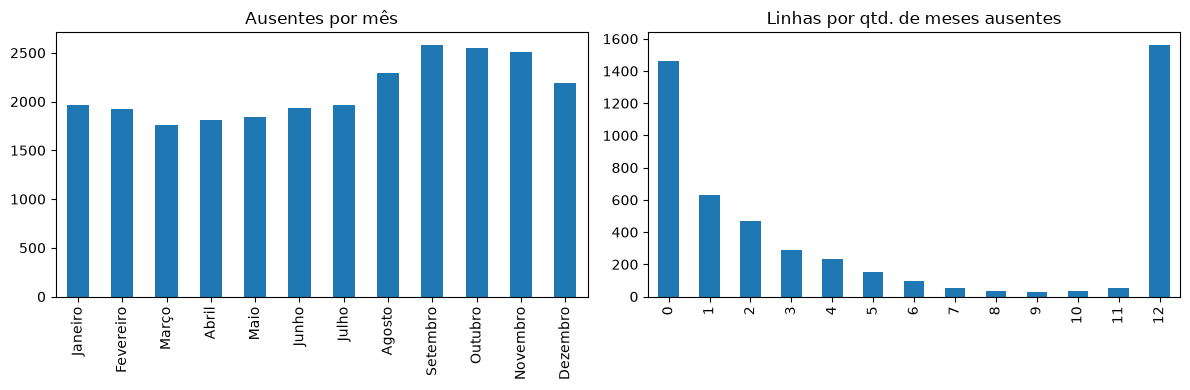

In [7]:
df = carregar(CSV_PATH)
X0, y0, g0 = X_y_grupos(df)

print(f"Instâncias: {len(X0)} | Atributos: {X0.shape[1]} | Classes: {y0.nunique()}")
display(y0.value_counts(normalize=True).round(3).to_frame('proporcao'))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
X0.isna().sum().plot(kind='bar', ax=ax[0], title='Ausentes por mês')
X0.isna().sum(axis=1).value_counts().sort_index().plot(kind='bar', ax=ax[1], title='Linhas por qtd. de meses ausentes')
plt.tight_layout()
plt.show()

# Hiperparâmetros 

Se precisar alterar algo, frequentemente é aqui que viremos


In [8]:
IMPUTADORES = {
    'mediana': lambda: SimpleImputer(strategy='median'),
    'knn_imputer': lambda: KNNImputer(n_neighbors=5),
}
SCALERS = {'standard': StandardScaler, 'minmax': MinMaxScaler, 'robust': RobustScaler}
KS = [1, 3, 5, 7, 9]
PESOS = ['uniform', 'distance']
METRICAS = ['euclidean', 'manhattan', 'chebyshev']
MAX_AUSENTES = [None, 6]

def filtrar(X, y, g, max_aus):
    if max_aus is None:
        return X, y, g
    ok = X.isna().sum(axis=1) <= max_aus
    return X[ok], y[ok], g[ok]

def montar_pipe(imp, sc, k, w, met):
    return Pipeline([
        ('imputer', IMPUTADORES[imp]()),
        ('scaler', SCALERS[sc]()),
        ('knn', KNeighborsClassifier(n_neighbors=k, weights=w, metric=met)),
    ])

# Experimentos

In [9]:
cv = StratifiedGroupKFold(n_splits=FOLDS, shuffle=True, random_state=SEED)
combos = list(itertools.product(MAX_AUSENTES, IMPUTADORES, SCALERS, KS, PESOS, METRICAS))

linhas, cache = [], {}
for i, (ma, imp, sc, k, w, met) in enumerate(combos, 1):
    if ma not in cache:
        cache[ma] = filtrar(X0, y0, g0, ma)
    X, y, g = cache[ma]
    t0 = time.time()
    r = cross_validate(
        montar_pipe(imp, sc, k, w, met), X, y, groups=g, cv=cv,
        n_jobs=-1, scoring=['accuracy', 'balanced_accuracy', 'f1_macro']
    )
    linhas.append(dict(
        id=i, max_ausentes=ma, n_instancias=len(X), imputador=imp, scaler=sc, k=k,
        pesos=w, metrica=met,
        acc=r['test_accuracy'].mean(), acc_std=r['test_accuracy'].std(),
        bal_acc=r['test_balanced_accuracy'].mean(),
        f1_macro=r['test_f1_macro'].mean(), f1_std=r['test_f1_macro'].std(),
        seg=round(time.time() - t0, 2)
    ))

res = pd.DataFrame(linhas).sort_values('f1_macro', ascending=False)
res.to_csv(os.path.join(PASTA_SAIDA, 'experimentos_knn.csv'), index=False)
display(res.head(10))

,id,max_ausentes,n_instancias,imputador,scaler,k,pesos,metrica,acc,acc_std,bal_acc,f1_macro,f1_std,seg
196,197,6.0,3337,mediana,standard,5,distance,manhattan,0.753701,0.035158,0.717196,0.722351,0.043573,0.11
226,227,6.0,3337,mediana,minmax,5,distance,manhattan,0.752508,0.033683,0.714649,0.721206,0.040105,0.11
232,233,6.0,3337,mediana,minmax,7,distance,manhattan,0.756999,0.034809,0.709665,0.719139,0.042837,0.12
316,317,6.0,3337,knn_imputer,minmax,5,distance,manhattan,0.746826,0.045579,0.717607,0.719137,0.056918,0.62
352,353,6.0,3337,knn_imputer,robust,7,distance,manhattan,0.748309,0.038125,0.714563,0.718610,0.048987,0.63
322,323,6.0,3337,knn_imputer,minmax,7,distance,manhattan,0.748914,0.046720,0.713580,0.718273,0.060696,0.63
298,299,6.0,3337,knn_imputer,standard,9,distance,manhattan,0.750696,0.039599,0.711581,0.717882,0.050849,0.62
346,347,6.0,3337,knn_imputer,robust,5,distance,manhattan,0.745325,0.047695,0.716051,0.717320,0.060991,0.61
286,287,6.0,3337,knn_imputer,standard,5,distance,manhattan,0.745013,0.042864,0.713984,0.717131,0.056642,0.61
358,359,6.0,3337,knn_imputer,robust,9,distance,manhattan,0.748898,0.038999,0.708335,0.716307,0.049010,0.62


# Avaliação

                            precision    recall  f1-score   support

      Agreste Pernambucano      0.763     0.806     0.784      1114
         Mata Pernambucana      0.762     0.721     0.741       752
   Metropolitana do Recife      0.801     0.812     0.806       367
       Sertão Pernambucano      0.753     0.780     0.766       836
São Francisco Pernambucano      0.592     0.466     0.522       268

                  accuracy                          0.754      3337
                 macro avg      0.734     0.717     0.724      3337
              weighted avg      0.751     0.754     0.751      3337



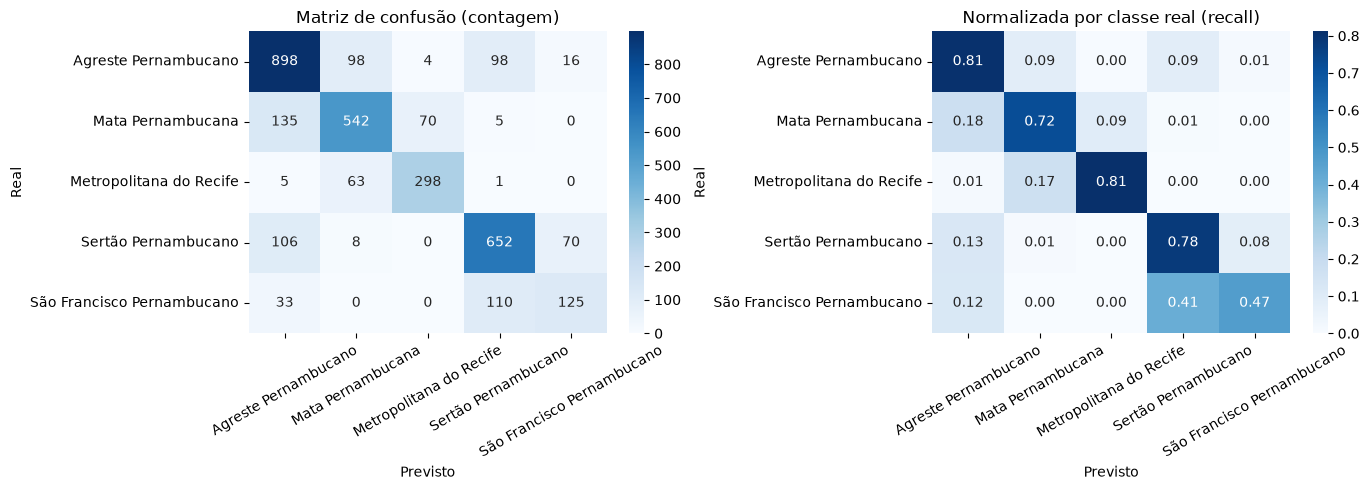

In [10]:
melhor = res.iloc[0].copy()
max_aus = None if pd.isna(melhor['max_ausentes']) else int(melhor['max_ausentes'])

X, y, g = filtrar(X0, y0, g0, max_aus)
pipe = montar_pipe(melhor['imputador'], melhor['scaler'], int(melhor['k']),
                   melhor['pesos'], melhor['metrica'])

pred = cross_val_predict(pipe, X, y, groups=g, cv=cv, n_jobs=-1)
probs = cross_val_predict(pipe, X, y, groups=g, cv=cv, n_jobs=-1, method='predict_proba')

classes = np.sort(y.unique())
print(classification_report(y, pred, labels=classes, digits=3))

cm = confusion_matrix(y, pred, labels=classes)
cm_df = pd.DataFrame(cm, index=classes, columns=classes)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues', ax=ax[0])
ax[0].set_title('Matriz de confusão (contagem)')
sns.heatmap(cm_df.div(cm_df.sum(axis=1), axis=0), annot=True, fmt='.2f', cmap='Blues', ax=ax[1])
ax[1].set_title('Normalizada por classe real (recall)')
for a in ax:
    a.set_xlabel('Previsto'); a.set_ylabel('Real')
    a.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

# Análise de erros

In [12]:
class_to_idx = {c: idx for idx, c in enumerate(classes)}
prob_real = probs[np.arange(len(y)), [class_to_idx[c] for c in y]]
prob_prev = probs[np.arange(len(y)), [class_to_idx[c] for c in pred]]

mask_erro = y.to_numpy() != pred
df_erros = df.loc[X.index[mask_erro]].copy()
df_erros.insert(0, 'indice_original', X.index[mask_erro])
df_erros.insert(1, 'classe_real', y.to_numpy()[mask_erro])
df_erros.insert(2, 'classe_prevista', pred[mask_erro])
df_erros.insert(3, 'prob_prevista', np.round(prob_prev[mask_erro], 3))
df_erros.insert(4, 'prob_classe_real', np.round(prob_real[mask_erro], 3))
df_erros.insert(5, 'qtd_meses_ausentes', X.isna().sum(axis=1).to_numpy()[mask_erro])

df_erros = df_erros.sort_values(by='prob_prevista', ascending=False)
df_erros.to_csv(os.path.join(PASTA_SAIDA, 'instancias_incorretas.csv'), index=False)

print(f"Erros: {len(df_erros)}/{len(X)} ({len(df_erros)/len(X):.1%})")
display(df_erros.groupby(['classe_real', 'classe_prevista']).size().sort_values(ascending=False).to_frame('qtd'))

# Exibe os 15 casos mais críticos (alta confiança na classe oposta)
display(df_erros.head(15))

Erros: 822/3337 (24.6%)


qtd
classe_real                classe_prevista                
Mata Pernambucana          Agreste Pernambucano        135
São Francisco Pernambucano Sertão Pernambucano         110
Sertão Pernambucano        Agreste Pernambucano        106
Agreste Pernambucano       Sertão Pernambucano          98
                           Mata Pernambucana            98
Mata Pernambucana          Metropolitana do Recife      70
Sertão Pernambucano        São Francisco Pernambucano   70
Metropolitana do Recife    Mata Pernambucana            63
São Francisco Pernambucano Agreste Pernambucano         33
Agreste Pernambucano       São Francisco Pernambucano   16
Sertão Pernambucano        Mata Pernambucana             8
Metropolitana do Recife    Agreste Pernambucano          5
Mata Pernambucana          Sertão Pernambucano           5
Agreste Pernambucano       Metropolitana do Recife       4
Metropolitana do Recife    Sertão Pernambucano           1

,indice_original,classe_real,classe_prevista,prob_prevista,prob_classe_real,qtd_meses_ausentes,Código,Posto,Ano,Janeiro,...,Junho,Julho,Agosto,Setembro,Outubro,Novembro,Dezembro,Meses ausentes,Cidade,Mesorregiao
62,62,Metropolitana do Recife,Mata Pernambucana,1.0,0.0,6,301,Cabo,2010,143.3,...,481.6,NaN,NaN,NaN,NaN,NaN,NaN,6,Cabo,Metropolitana do Recife
3074,3074,Agreste Pernambucano,Sertão Pernambucano,1.0,0.0,4,208,Pedra (São Pedro do Cordeiro),2019,4.0,...,39.0,31.0,14.0,NaN,NaN,NaN,NaN,4,Pedra,Agreste Pernambucano
4958,4958,Sertão Pernambucano,Agreste Pernambucano,1.0,0.0,3,478,Manari,2025,57.7,...,94.9,48.8,123.2,64.8,NaN,50.0,NaN,3,Manari,Sertão Pernambucano
5038,5038,Agreste Pernambucano,Sertão Pernambucano,1.0,0.0,1,21,São Bento do Una (IPA),2025,164.3,...,130.5,41.0,56.3,22.8,3.1,1.7,NaN,1,São Bento do Una,Agreste Pernambucano
5051,5051,Metropolitana do Recife,Mata Pernambucana,1.0,0.0,0,267,São Lourenço da Mata (Tapacurá),2025,141.8,...,205.0,141.1,148.3,80.1,44.2,0.8,25.2,0,São Lourenço da Mata,Metropolitana do Recife
2904,2904,Agreste Pernambucano,Mata Pernambucana,1.0,0.0,0,459,Barra de Guabiraba,2019,151.9,...,283.9,320.3,220.7,92.4,35.0,3.1,33.6,0,Barra de Guabiraba,Agreste Pernambucano
5052,5052,Agreste Pernambucano,Mata Pernambucana,1.0,0.0,0,271,São Vicente Férrer,2025,204.7,...,258.3,233.1,182.2,87.2,81.0,4.9,4.9,0,São Vicente Férrer,Agreste Pernambucano
4800,4800,Metropolitana do Recife,Mata Pernambucana,1.0,0.0,3,309,Araçoiaba (Granja Cristo Redentor),2025,NaN,...,221.4,229.7,182.7,54.4,101.6,NaN,4.5,3,Araçoiaba,Metropolitana do Recife
4816,4816,Sertão Pernambucano,Agreste Pernambucano,1.0,0.0,2,16,Arcoverde (INMET),2025,203.5,...,121.7,30.2,61.3,55.9,14.6,NaN,NaN,2,Arcoverde,Sertão Pernambucano
1780,1780,Agreste Pernambucano,Mata Pernambucana,1.0,0.0,1,463,Orobó,2015,5.5,...,134.1,205.5,43.0,1.0,8.0,NaN,152.5,1,Orobó,Agreste Pernambucano
